# Résidences Azur : anticiper les annulations de séjour

**Objectif.** Estimer, au moment où une réservation est enregistrée, la probabilité qu'elle soit annulée, puis décider si l'équipe commerciale doit appeler le client pour confirmer.

Plan : 1. cadrage · 2. audit des variables · 3. exploration · 4. variables dérivées · 5. protocole · 6. échelle de méthodes · 7. sélection · 8. évaluation et seuil · 9. diagnostic · 10. interprétation · 11. sauvegarde.

In [1]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.inspection import permutation_importance
from sklearn.metrics import (average_precision_score, roc_auc_score, roc_curve,
                             precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay,
                             precision_score, recall_score)
from features import add_features, RAW_COLUMNS, NUMERIC_FEATURES, CATEGORICAL_FEATURES, EXCLUDED

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
SEED = 0
TARGET = "annule"
df = pd.read_csv("../data/reservations_azur.csv")
print(df.shape)
df.head(3)

(112188, 32)


,id_reservation,site,annule,date_reservation,date_arrivee,nuits_week_end,nuits_semaine,nb_adultes,nb_enfants,nb_bebes,formule,pays_client,origine_commerciale,canal_vente,client_fidele,annulations_passees,sejours_honores_passes,logement_demande,logement_attribue,nb_modifications,garantie,id_agence,id_entreprise,jours_attente_confirmation,profil_client,tarif_nuit,nb_places_parking,nb_demandes_speciales,code_promo,indice_affinite,statut_dossier,date_statut
0,R000001,Littoral,0,2020-07-24,2021-07-01,0,0,2,0.0,0,Petit-déjeuner,FRA,Direct,Direct,0,0,0,L10,L10,3,Aucune,NaN,NaN,0,Individuel,0,0,0,AZ203,0.505,Séjour effectué,2021-07-01
1,R000002,Littoral,0,2019-06-25,2021-07-01,0,0,2,0.0,0,Petit-déjeuner,FRA,Direct,Direct,0,0,0,L10,L10,4,Aucune,NaN,NaN,0,Individuel,0,0,0,AZ540,0.138,Séjour effectué,2021-07-01
2,R000003,Littoral,0,2021-06-24,2021-07-01,0,1,1,0.0,0,Petit-déjeuner,GBR,Direct,Direct,0,0,0,L07,L10,0,Aucune,NaN,NaN,0,Individuel,88,0,0,AZ540,0.163,Séjour effectué,2021-07-02


## 1. Cadrage : métrique et décision métier

**Qui décide ?** L'équipe commerciale appelle les clients dont la réservation est jugée à risque. Le modèle ne décide pas seul : il classe les réservations, un humain appelle.

**Seuil économique.** Un appel coûte 6 € et évite l'annulation une fois sur trois ; une annulation évitée vaut 100 €. Appeler une réservation de probabilité *p* rapporte en moyenne *p* × (1/3) × 100 − 6 €. C'est positif si **p > 6 / 33,3 = 0,18**. Le seuil par défaut de l'application est donc **0,18**, réglable par un curseur.

**Métrique principale : l'AUPRC** (aire sous la courbe précision-rappel). Elle juge la capacité du modèle à placer les annulations en tête, quel que soit le seuil, et reste honnête quand la classe positive est minoritaire (environ 25 % après dédoublonnage). On suit aussi l'AUC ROC, et surtout le **gain net en euros** au seuil choisi, qui traduit la qualité du modèle en décision.

In [2]:
COUT_APPEL, TAUX_SUCCES, VALEUR = 6, 1/3, 100
SEUIL_ECO = COUT_APPEL / (TAUX_SUCCES * VALEUR)
print(f"Seuil économique : appeler si p > {SEUIL_ECO:.2f}")

def gain_net(y, proba, seuil):
    """Gain en euros si on appelle toutes les réservations de probabilité >= seuil."""
    appel = proba >= seuil
    return (y[appel] * TAUX_SUCCES * VALEUR).sum() - COUT_APPEL * appel.sum()

Seuil économique : appeler si p > 0.18


## 2. Audit des variables

Pour chaque colonne : est-elle **connue à l'instant où la réservation est enregistrée** ? Est-elle **utile** ? Les chiffres ci-dessous justifient les exclusions.

In [3]:
# Preuves de fuite : des variables qui « connaissent » déjà la réponse
print(pd.crosstab(df["statut_dossier"], df[TARGET]))
diff = df["logement_demande"] != df["logement_attribue"]
print("\nAnnulation si logement attribué ≠ demandé :", round(df.loc[diff, TARGET].mean(), 3),
      "| sinon :", round(df.loc[~diff, TARGET].mean(), 3))
print("Annulation si au moins une place de parking :", round(df.loc[df.nb_places_parking > 0, TARGET].mean(), 3),
      "| sans parking :", round(df.loc[df.nb_places_parking == 0, TARGET].mean(), 3))
print("Annulation selon le nombre de modifications :")
print(df.groupby(df.nb_modifications.clip(upper=3))[TARGET].mean().round(3).to_dict())

annule                  0      1
statut_dossier                  
Absent non prévenu      0    995
Annulé                  0  36027
Séjour effectué     75166      0

Annulation si logement attribué ≠ demandé : 0.045 | sinon : 0.373
Annulation si au moins une place de parking : 0.0 | sans parking : 0.353
Annulation selon le nombre de modifications :
{0: 0.366, 1: 0.122, 2: 0.178, 3: 0.137}


In [4]:
# Variables sans lien avec la cible
print("Corrélation indice_affinite / annule :", round(df["indice_affinite"].corr(df[TARGET]), 4))
print("Taux d'annulation par code promo :")
print(df.groupby("code_promo")[TARGET].mean().round(3).sort_values().to_dict())

Corrélation indice_affinite / annule : -0.007
Taux d'annulation par code promo :
{'AZ718': 0.315, 'AZ588': 0.315, 'AZ919': 0.315, 'AZ203': 0.32, 'AZ387': 0.322, 'AZ912': 0.324, 'AZ837': 0.326, 'AZ593': 0.34, 'AZ540': 0.343, 'AZ626': 0.343, 'AZ493': 0.347, 'AZ742': 0.35}


**Démonstration de la fuite.** Si l'on garde ces variables, un modèle obtient un score « parfait » : trop beau pour être vrai, et inutilisable au moment de la réservation.

In [5]:
# Un boosting entraîné UNIQUEMENT sur les variables fuyantes (découpage aléatoire, pour l'exemple)
from sklearn.model_selection import train_test_split
fuite = pd.DataFrame({
    "statut": df["statut_dossier"].astype("category").cat.codes,
    "parking": df["nb_places_parking"],
    "logement_change": (df["logement_demande"] != df["logement_attribue"]).astype(int),
    "nb_modifications": df["nb_modifications"],
})
Xf_tr, Xf_te, yf_tr, yf_te = train_test_split(fuite, df[TARGET], test_size=0.3, random_state=SEED)
m_fuite = HistGradientBoostingClassifier(random_state=SEED).fit(Xf_tr, yf_tr)
print("AUPRC avec les seules variables fuyantes :", round(average_precision_score(yf_te, m_fuite.predict_proba(Xf_te)[:, 1]), 3))

AUPRC avec les seules variables fuyantes : 1.0


### Conclusion de l'audit

**Exclues pour fuite d'information (inconnues à l'enregistrement) :**
- `statut_dossier` et `date_statut` : le statut *est* la réponse (100 % d'annulations pour « Annulé », 0 % pour « Séjour effectué »).
- `logement_attribue` : attribué à l'arrivée. Quand il diffère du logement demandé, l'annulation tombe à 4,5 % contre 37 % : le client était donc présent.
- `nb_places_parking` : 0 % d'annulation dès qu'une place est demandée, signe qu'elle est saisie à l'arrivée.
- `nb_modifications` et `jours_attente_confirmation` : ils s'accumulent *après* l'enregistrement (à l'instant de la réservation, ils valent 0).

**Exclues car inutiles :** `id_reservation` (identifiant), `code_promo` (12 codes, tous entre 31,5 % et 35 % d'annulation, comme la moyenne), `indice_affinite` (corrélation −0,007, et origine inconnue).

**Conservées avec réserve :** `pays_client` et `nb_demandes_speciales` sont normalement connus à la réservation, mais pourraient être complétés plus tard : à confirmer avec le métier (on mesure leur poids en section 7). Le tableau complet est dans `audit_variables.md`.

## 3. Exploration des données (EDA)

Taux d'annulation global : 0.33


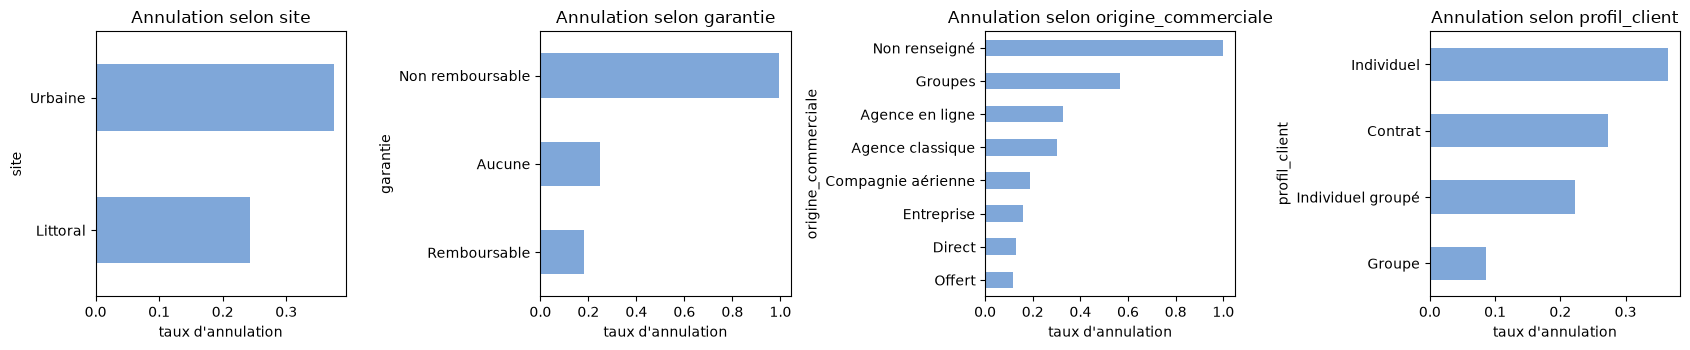

In [6]:
print("Taux d'annulation global :", round(df[TARGET].mean(), 3))
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
for ax, col in zip(axes, ["site", "garantie", "origine_commerciale", "profil_client"]):
    df.groupby(col)[TARGET].mean().sort_values().plot.barh(ax=ax, color="#7FA7D9")
    ax.set_title(f"Annulation selon {col}"); ax.set_xlabel("taux d'annulation")
plt.tight_layout(); plt.show()

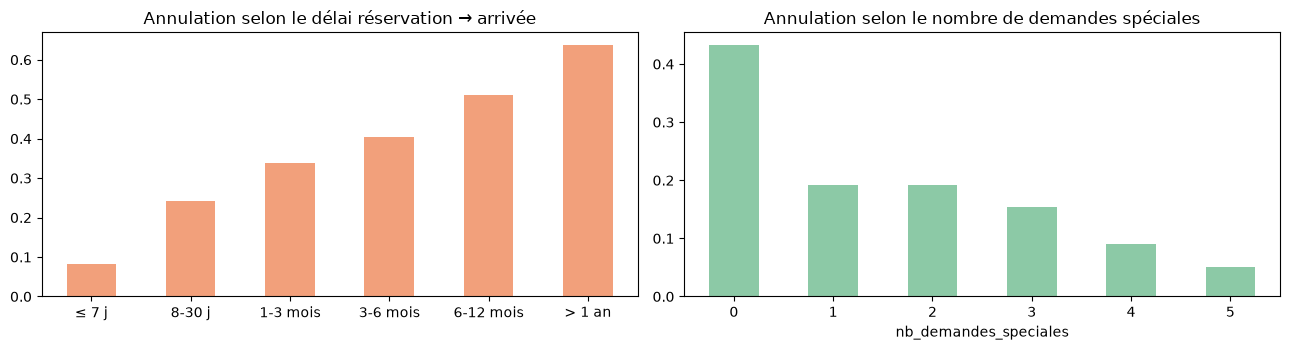

In [7]:
delai = (pd.to_datetime(df.date_arrivee) - pd.to_datetime(df.date_reservation)).dt.days
tranche = pd.cut(delai, [-1, 7, 30, 90, 180, 365, 800],
                 labels=["≤ 7 j", "8-30 j", "1-3 mois", "3-6 mois", "6-12 mois", "> 1 an"])
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
df.groupby(tranche, observed=True)[TARGET].mean().plot.bar(ax=axes[0], color="#F2A07B", rot=0)
axes[0].set_title("Annulation selon le délai réservation → arrivée")
df.groupby(df.nb_demandes_speciales)[TARGET].mean().plot.bar(ax=axes[1], color="#8CC9A6", rot=0)
axes[1].set_title("Annulation selon le nombre de demandes spéciales")
plt.tight_layout(); plt.show()

In [8]:
# Valeurs manquantes : que signifient-elles ?
na = df.isna().sum(); print(na[na > 0])
print("\nAnnulation sans agence :", round(df.loc[df.id_agence.isna(), TARGET].mean(), 3),
      "| avec agence :", round(df.loc[df.id_agence.notna(), TARGET].mean(), 3))
print("Annulation sans entreprise :", round(df.loc[df.id_entreprise.isna(), TARGET].mean(), 3),
      "| avec entreprise :", round(df.loc[df.id_entreprise.notna(), TARGET].mean(), 3))

nb_enfants            3
pays_client         474
id_agence         15678
id_entreprise    105594
dtype: int64

Annulation sans agence : 0.215 | avec agence : 0.349
Annulation sans entreprise : 0.341 | avec entreprise : 0.15


Tarif ≤ 0 : 1917 | tarif > 1000 : 1 | max : 6372
0 adulte : 385 | plus de 10 adultes : 10
Séjour de 0 nuit : 705 | plus de 30 nuits : 23


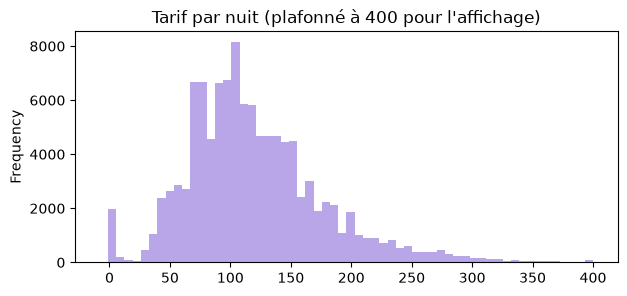

In [9]:
# Valeurs aberrantes
nuits = df.nuits_week_end + df.nuits_semaine
print("Tarif ≤ 0 :", (df.tarif_nuit <= 0).sum(), "| tarif > 1000 :", (df.tarif_nuit > 1000).sum(),
      "| max :", df.tarif_nuit.max())
print("0 adulte :", (df.nb_adultes == 0).sum(), "| plus de 10 adultes :", (df.nb_adultes > 10).sum())
print("Séjour de 0 nuit :", (nuits == 0).sum(), "| plus de 30 nuits :", (nuits > 30).sum())
df.tarif_nuit.clip(upper=400).plot.hist(bins=60, figsize=(7, 3), color="#B9A6E8", title="Tarif par nuit (plafonné à 400 pour l'affichage)"); plt.show()

In [10]:
# Lignes identiques (hors identifiant)
dup = df.drop(columns="id_reservation").duplicated(keep=False)
print("Lignes en double :", df.drop(columns="id_reservation").duplicated().sum(),
      f"({df.drop(columns='id_reservation').duplicated().mean():.1%})")
print("Annulation parmi les lignes dupliquées :", round(df.loc[dup, TARGET].mean(), 3),
      "| parmi les autres :", round(df.loc[~dup, TARGET].mean(), 3))

Lignes en double : 28204 (25.1%)
Annulation parmi les lignes dupliquées : 0.534 | parmi les autres : 0.235


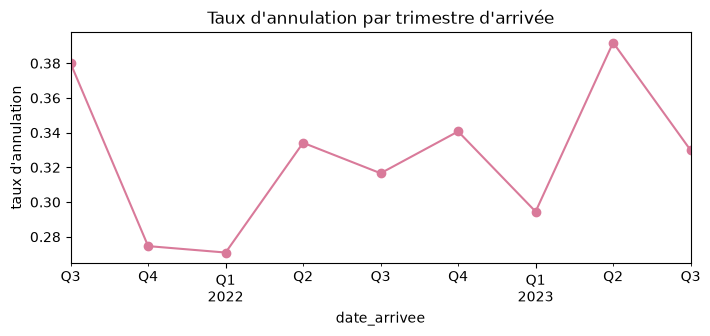

Réservations de 2019-06-25 à 2023-08-31


In [11]:
# Évolution dans le temps
trimestre = pd.to_datetime(df.date_arrivee).dt.to_period("Q")
ax = df.groupby(trimestre)[TARGET].mean().plot(marker="o", figsize=(8, 3), color="#D97A9A",
                                               title="Taux d'annulation par trimestre d'arrivée")
ax.set_ylabel("taux d'annulation"); plt.show()
print("Réservations de", df.date_reservation.min(), "à", df.date_reservation.max())

### Constats de l'exploration

1. **Lignes identiques : 28 204 (25 %).** Elles sont très annulées (53 % contre 23,5 %) : ce sont surtout des réservations de groupe saisies en plusieurs exemplaires. Gardées, elles gonfleraient le score si une copie tombait dans l'entraînement et l'autre dans le test. **Décision : supprimées avant tout découpage** (le taux d'annulation passe de 33 % à 24,5 %).
2. **Le délai de réservation est le premier signal métier.** 8 % d'annulation quand on réserve moins d'une semaine avant, plus de 50 % au-delà d'un an. D'où la variable dérivée `delai_jours`.
3. **Segments très contrastés.** Site urbain 37,5 % contre littoral 24 %. Garantie « non remboursable » : 99 % d'annulations (surprenant, à faire confirmer par le métier, mais connue à la réservation donc conservée). Origine « Groupes » 57 %, « Direct » 13 %. Plus le client fait de demandes spéciales, moins il annule (43 % sans demande, 5 % avec cinq).
4. **Valeurs manquantes porteuses de sens.** `id_entreprise` manque à 94 % et `id_agence` à 14 % : le manquant signifie « pas d'intermédiaire », d'où les indicateurs `via_agence` / `via_entreprise` plutôt qu'une imputation. 474 pays manquants → « Inconnu » ; 3 nombres d'enfants manquants → 0.
5. **Valeurs aberrantes.** 1 917 tarifs ≤ 0 et un tarif à 6 372 € : ramenés dans [0 ; 1 000]. 385 réservations à 0 adulte et 705 séjours de 0 nuit : gardés (erreurs de saisie ou séjours de jour), car peu nombreux.
6. **Le taux varie dans le temps** (27 % à 39 % selon le trimestre d'arrivée) : il faut un **découpage chronologique** pour évaluer comme en production.

## 4. Ingénierie des variables

Les fonctions sont dans **`features.py`**, appelées dans le pipeline par un `FunctionTransformer` (ainsi `model.pkl` refait exactement les mêmes calculs en production). Variables dérivées créées :

| Variable | Calcul | Pourquoi |
|---|---|---|
| `delai_jours` | date d'arrivée − date de réservation | plus on réserve tôt, plus on a le temps de changer d'avis |
| `nb_nuits`, `part_week_end` | durée totale, part de nuits de week-end | séjour long ou court, loisir ou travail |
| `nb_personnes`, `avec_enfants` | adultes + enfants + bébés | une famille annule moins facilement |
| `tarif_par_personne` | tarif nettoyé / personnes | prix ressenti |
| `a_deja_annule` | annulations passées > 0 | comportement passé du client |
| `via_agence`, `via_entreprise`, `agence` | présence d'un code agence / entreprise | le manquant signifie « pas d'intermédiaire » |
| `mois_sin`, `mois_cos`, `jour_arrivee_sin/cos`, `saison` | calendrier de l'arrivée, encodé sur un cercle | saisonnalité ; décembre voisin de janvier |

**Autres traitements.** Tarif ramené dans [0 ; 1 000] € (valeurs négatives et 6 372 € jugées erronées). Enfants manquants (3) = 0 ; pays manquant = « Inconnu ». **Modalités rares** (moins de 50 réservations : petits pays, agences rares) regroupées par `OneHotEncoder(min_frequency=50, handle_unknown="infrequent_if_exist")`, qui traite aussi une catégorie jamais vue. Nombres standardisés pour les modèles linéaires et le réseau.

In [12]:
def preprocess(scale=True):
    num = StandardScaler() if scale else "passthrough"
    cat = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50, sparse_output=False)
    return ColumnTransformer([("num", num, NUMERIC_FEATURES), ("cat", cat, CATEGORICAL_FEATURES)])

def pipeline(model, scale=True):
    """Préparation complète + modèle, dans un seul objet."""
    return make_pipeline(FunctionTransformer(add_features), preprocess(scale), model)

add_features(df.head(3)[RAW_COLUMNS])

,delai_jours,nb_nuits,part_week_end,nb_personnes,avec_enfants,nuits_week_end,nuits_semaine,nb_adultes,client_fidele,annulations_passees,sejours_honores_passes,a_deja_annule,tarif_nuit,tarif_par_personne,nb_demandes_speciales,via_agence,via_entreprise,mois_sin,mois_cos,jour_arrivee_sin,jour_arrivee_cos,site,formule,pays_client,origine_commerciale,canal_vente,logement_demande,garantie,profil_client,agence,saison
0,342,0,0.0,2.0,0,0,0,2,0,0,0,0,0,0.0,0,0,0,-0.5,-0.866025,0.433884,-0.900969,Littoral,Petit-déjeuner,FRA,Direct,Direct,L10,Aucune,Individuel,0,ete
1,737,0,0.0,2.0,0,0,0,2,0,0,0,0,0,0.0,0,0,0,-0.5,-0.866025,0.433884,-0.900969,Littoral,Petit-déjeuner,FRA,Direct,Direct,L10,Aucune,Individuel,0,ete
2,7,1,0.0,1.0,0,0,1,1,0,0,0,0,88,88.0,0,0,0,-0.5,-0.866025,0.433884,-0.900969,Littoral,Petit-déjeuner,GBR,Direct,Direct,L07,Aucune,Individuel,0,ete


## 5. Protocole d'évaluation

1. **Dédoublonnage.** Les lignes identiques sont supprimées avant tout découpage : sinon une même réservation peut se retrouver à la fois en entraînement et en test, et le score devient trop optimiste.
2. **Découpage chronologique** sur la date de réservation : les 80 % les plus anciennes pour l'entraînement, les 20 % les plus récentes pour le test. C'est la situation réelle : on apprend sur le passé et on prédit les réservations à venir.
3. Dans l'entraînement, les **20 % les plus récents servent de validation** pour régler la profondeur de l'arbre et vérifier le seuil. Le test n'est utilisé qu'une fois, à la fin.

In [13]:
data = df.drop(columns="id_reservation").drop_duplicates().sort_values("date_reservation").reset_index(drop=True)
coupe = int(len(data) * 0.8)
train, test = data.iloc[:coupe], data.iloc[coupe:]
coupe_val = int(len(train) * 0.8)
fit_part, val = train.iloc[:coupe_val], train.iloc[coupe_val:]

X_train, y_train = train[RAW_COLUMNS], train[TARGET].to_numpy()
X_test, y_test = test[RAW_COLUMNS], test[TARGET].to_numpy()
print(f"{len(data)} réservations après dédoublonnage (taux d'annulation {data[TARGET].mean():.3f})")
print(f"Entraînement : {len(train)} ({train.date_reservation.min()} → {train.date_reservation.max()}), annulation {y_train.mean():.3f}")
print(f"Test : {len(test)} ({test.date_reservation.min()} → {test.date_reservation.max()}), annulation {y_test.mean():.3f}")

83984 réservations après dédoublonnage (taux d'annulation 0.245)
Entraînement : 67187 (2019-06-25 → 2023-01-28), annulation 0.245
Test : 16797 (2023-01-28 → 2023-08-31), annulation 0.246


### Vérification 1 : que donnerait un protocole naïf ?

Même boosting, mais découpage **aléatoire** et **doublons conservés** : le score est artificiellement gonflé, car des copies de la même réservation se retrouvent dans l'entraînement et le test.

In [14]:
from sklearn.model_selection import train_test_split
Xn_tr, Xn_te, yn_tr, yn_te = train_test_split(df[RAW_COLUMNS], df[TARGET], test_size=0.2, random_state=SEED)
m_naif = pipeline(HistGradientBoostingClassifier(max_iter=400, learning_rate=0.08, random_state=SEED), scale=False)
m_naif.fit(Xn_tr, yn_tr)
print("AUPRC protocole naïf (aléatoire + doublons) :", round(average_precision_score(yn_te, m_naif.predict_proba(Xn_te)[:, 1]), 3))

AUPRC protocole naïf (aléatoire + doublons) : 0.905


### Vérification 2 : découper sur la date de réservation ou sur la date d'arrivée ?

Les données s'arrêtent aux **arrivées** du 31 août 2023. Parmi les réservations les plus récentes, on ne voit donc que celles dont l'arrivée a déjà eu lieu : les réservations récentes à **long délai** manquent (elles arriveront après la fin des données). Notre test contient donc surtout des réservations à court délai, plus faciles à prédire comme « non annulées ».

On vérifie la robustesse de nos conclusions avec un second découpage : entraînement sur les **arrivées** de 2021-2022, test sur les arrivées de 2023 (c'est aussi ce qui se passe en production : on ne connaît l'issue d'une réservation qu'une fois la date d'arrivée passée).

In [15]:
delai_data = (pd.to_datetime(data.date_arrivee) - pd.to_datetime(data.date_reservation)).dt.days
delai_test = (pd.to_datetime(test.date_arrivee) - pd.to_datetime(test.date_reservation)).dt.days
print(f"Délai médian réservation -> arrivée : {delai_data.median():.0f} jours sur l'ensemble, "
      f"{delai_test.median():.0f} jours dans notre test (biais vers les courts délais)")

train_a = data[data.date_arrivee < "2023-01-01"]
test_a = data[data.date_arrivee >= "2023-01-01"]
print(f"Découpage sur l'arrivée : entraînement {len(train_a)}, test {len(test_a)} (taux d'annulation {test_a[TARGET].mean():.3f})")
for nom, modele in [("Baseline", DummyClassifier(strategy="prior")),
                    ("Régression logistique", LogisticRegression(max_iter=2000)),
                    ("Gradient boosting", HistGradientBoostingClassifier(max_iter=400, learning_rate=0.08, random_state=SEED))]:
    m = pipeline(modele, scale=isinstance(modele, LogisticRegression)).fit(train_a[RAW_COLUMNS], train_a[TARGET])
    p = m.predict_proba(test_a[RAW_COLUMNS])[:, 1]
    print(f"  {nom:22s} AUPRC {average_precision_score(test_a[TARGET], p):.3f} | AUC {roc_auc_score(test_a[TARGET], p):.3f} | "
          f"gain au seuil 0,18 : {gain_net(test_a[TARGET].to_numpy(), p, SEUIL_ECO):,.0f} €")

Délai médian réservation -> arrivée : 48 jours sur l'ensemble, 29 jours dans notre test (biais vers les courts délais)
Découpage sur l'arrivée : entraînement 53793, test 30191 (taux d'annulation 0.285)
  Baseline               AUPRC 0.285 | AUC 0.500 | gain au seuil 0,18 : 105,921 €
  Régression logistique  AUPRC 0.625 | AUC 0.810 | gain au seuil 0,18 : 143,119 €
  Gradient boosting      AUPRC 0.645 | AUC 0.825 | gain au seuil 0,18 : 140,928 €


**Conclusion des deux vérifications.**
- Le protocole naïf afficherait une AUPRC d'environ 0,90 contre 0,60 avec notre protocole : dédoublonner et découper dans le temps est indispensable pour une évaluation honnête.
- Avec le découpage sur la date d'arrivée, **le classement des modèles est le même** (boosting 0,645 > logistique 0,625 > baseline 0,285) : nos conclusions ne dépendent pas du découpage choisi. Les gains en euros ne sont pas comparables entre les deux tests (période et taux d'annulation différents). Au seuil 0,18, logistique et boosting rapportent à peu près autant : l'écart entre les deux modèles reste modeste.
- Nous gardons le découpage sur la date de réservation pour la suite (il correspond à l'ordre dans lequel le modèle reçoit les réservations), en gardant en tête son biais vers les courts délais.

## 6. Échelle de méthodes

Même découpage, même métrique (AUPRC sur le test), temps d'entraînement mesuré. L'AUPRC d'entraînement est affichée pour repérer le sur-apprentissage.

In [16]:
results = []
def evaluate(nom, model, Xtr=None, Xte=None):
    Xtr = X_train if Xtr is None else Xtr
    Xte = X_test if Xte is None else Xte
    t = time.perf_counter(); model.fit(Xtr, y_train); duree = time.perf_counter() - t
    p_test, p_train = model.predict_proba(Xte)[:, 1], model.predict_proba(Xtr)[:, 1]
    row = {"modèle": nom, "AUPRC test": average_precision_score(y_test, p_test),
           "AUC test": roc_auc_score(y_test, p_test), "AUPRC entraînement": average_precision_score(y_train, p_train),
           f"gain test au seuil {SEUIL_ECO:.2f} (€)": gain_net(y_test, p_test, SEUIL_ECO), "temps (s)": duree}
    results.append(row); print({k: round(v, 3) if isinstance(v, float) else v for k, v in row.items()})
    return model

In [17]:
# 1. Baseline : probabilité constante = taux d'annulation de l'entraînement
evaluate("1. Baseline (taux moyen)", DummyClassifier(strategy="prior"))

# 2a. Régression logistique SANS variables dérivées : colonnes brutes seulement (pas de dates)
brut_num = ["nuits_week_end", "nuits_semaine", "nb_adultes", "client_fidele", "annulations_passees",
            "sejours_honores_passes", "tarif_nuit", "nb_demandes_speciales"]
brut_cat = ["site", "formule", "pays_client", "origine_commerciale", "canal_vente", "logement_demande",
            "garantie", "profil_client"]
logit_brut = make_pipeline(
    ColumnTransformer([("num", make_pipeline(StandardScaler()), brut_num),
                       ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50, sparse_output=False), brut_cat)]),
    LogisticRegression(max_iter=3000))
Xb_tr, Xb_te = X_train.fillna({"pays_client": "Inconnu"}), X_test.fillna({"pays_client": "Inconnu"})
evaluate("2a. Logistique sans variables dérivées", logit_brut, Xb_tr, Xb_te)

# 2b. Régression logistique AVEC variables dérivées
_ = evaluate("2b. Logistique avec variables dérivées", pipeline(LogisticRegression(max_iter=3000)))

{'modèle': '1. Baseline (taux moyen)', 'AUPRC test': np.float64(0.246), 'AUC test': np.float64(0.5), 'AUPRC entraînement': np.float64(0.245), 'gain test au seuil 0.18 (€)': np.float64(36784.667), 'temps (s)': 0.002}


{'modèle': '2a. Logistique sans variables dérivées', 'AUPRC test': np.float64(0.495), 'AUC test': np.float64(0.756), 'AUPRC entraînement': np.float64(0.576), 'gain test au seuil 0.18 (€)': np.float64(57835.333), 'temps (s)': 2.231}


{'modèle': '2b. Logistique avec variables dérivées', 'AUPRC test': np.float64(0.531), 'AUC test': np.float64(0.792), 'AUPRC entraînement': np.float64(0.663), 'gain test au seuil 0.18 (€)': np.float64(60702.0), 'temps (s)': 5.215}


In [18]:
# 3. Arbres : profondeur faible, choisie sur la validation, illimitée
scores_prof = {}
for d in [2, 3, 4, 6, 8, 10, 12, 15, 20]:
    m = pipeline(DecisionTreeClassifier(max_depth=d, min_samples_leaf=20, random_state=SEED), scale=False)
    m.fit(fit_part[RAW_COLUMNS], fit_part[TARGET])
    scores_prof[d] = average_precision_score(val[TARGET], m.predict_proba(val[RAW_COLUMNS])[:, 1])
PROF = max(scores_prof, key=scores_prof.get)
print("AUPRC de validation selon la profondeur :", {k: round(v, 3) for k, v in scores_prof.items()}, "→ profondeur", PROF)

evaluate("3a. Arbre, profondeur 3", pipeline(DecisionTreeClassifier(max_depth=3, random_state=SEED), scale=False))
evaluate(f"3b. Arbre, profondeur {PROF} (validation)", pipeline(DecisionTreeClassifier(max_depth=PROF, min_samples_leaf=20, random_state=SEED), scale=False))
_ = evaluate("3c. Arbre, profondeur illimitée", pipeline(DecisionTreeClassifier(random_state=SEED), scale=False))

AUPRC de validation selon la profondeur : {2: np.float64(0.346), 3: np.float64(0.42), 4: np.float64(0.535), 6: np.float64(0.575), 8: np.float64(0.601), 10: np.float64(0.609), 12: np.float64(0.602), 15: np.float64(0.59), 20: np.float64(0.578)} → profondeur 10


{'modèle': '3a. Arbre, profondeur 3', 'AUPRC test': np.float64(0.404), 'AUC test': np.float64(0.718), 'AUPRC entraînement': np.float64(0.455), 'gain test au seuil 0.18 (€)': np.float64(53942.0), 'temps (s)': 1.214}


{'modèle': '3b. Arbre, profondeur 10 (validation)', 'AUPRC test': np.float64(0.54), 'AUC test': np.float64(0.8), 'AUPRC entraînement': np.float64(0.735), 'gain test au seuil 0.18 (€)': np.float64(56884.667), 'temps (s)': 1.639}


{'modèle': '3c. Arbre, profondeur illimitée', 'AUPRC test': np.float64(0.342), 'AUC test': np.float64(0.636), 'AUPRC entraînement': np.float64(1.0), 'gain test au seuil 0.18 (€)': np.float64(36500.667), 'temps (s)': 2.128}


In [19]:
# 4. Forêt aléatoire
evaluate("4. Forêt aléatoire (300 arbres)", pipeline(RandomForestClassifier(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=SEED), scale=False))

# 5. Gradient boosting
hgb = evaluate("5. Gradient boosting (HistGB)", pipeline(HistGradientBoostingClassifier(max_iter=400, learning_rate=0.08, random_state=SEED), scale=False))

# 6. Bonus : perceptron multicouche (2 couches cachées de 64 neurones, arrêt précoce)
_ = evaluate("6. Bonus : MLP (64, 64)", pipeline(MLPClassifier(hidden_layer_sizes=(64, 64), alpha=1e-3, early_stopping=True,
                                                          max_iter=200, random_state=SEED)))

{'modèle': '4. Forêt aléatoire (300 arbres)', 'AUPRC test': np.float64(0.588), 'AUC test': np.float64(0.83), 'AUPRC entraînement': np.float64(0.906), 'gain test au seuil 0.18 (€)': np.float64(68944.667), 'temps (s)': 15.429}


{'modèle': '5. Gradient boosting (HistGB)', 'AUPRC test': np.float64(0.6), 'AUC test': np.float64(0.836), 'AUPRC entraînement': np.float64(0.822), 'gain test au seuil 0.18 (€)': np.float64(64519.333), 'temps (s)': 11.837}


{'modèle': '6. Bonus : MLP (64, 64)', 'AUPRC test': np.float64(0.591), 'AUC test': np.float64(0.819), 'AUPRC entraînement': np.float64(0.809), 'gain test au seuil 0.18 (€)': np.float64(62941.333), 'temps (s)': 13.057}


In [20]:
table = pd.DataFrame(results).set_index("modèle").round(3)
table

,AUPRC test,AUC test,AUPRC entraînement,gain test au seuil 0.18 (€),temps (s)
modèle,,,,,
1. Baseline (taux moyen),0.246,0.500,0.245,36784.667,0.002
2a. Logistique sans variables dérivées,0.495,0.756,0.576,57835.333,2.231
2b. Logistique avec variables dérivées,0.531,0.792,0.663,60702.000,5.215
"3a. Arbre, profondeur 3",0.404,0.718,0.455,53942.000,1.214
"3b. Arbre, profondeur 10 (validation)",0.540,0.800,0.735,56884.667,1.639
"3c. Arbre, profondeur illimitée",0.342,0.636,1.000,36500.667,2.128
4. Forêt aléatoire (300 arbres),0.588,0.830,0.906,68944.667,15.429
5. Gradient boosting (HistGB),0.600,0.836,0.822,64519.333,11.837
"6. Bonus : MLP (64, 64)",0.591,0.819,0.809,62941.333,13.057


### Lecture de l'échelle (AUPRC sur le test ; le hasard vaut 0,246)

| Palier | AUPRC | Ce qui explique l'écart avec le palier précédent |
|---|---|---|
| 1. Baseline | 0,246 | Probabilité constante : AUC de 0,5, aucun classement. Au seuil 0,18, elle revient à appeler tout le monde. |
| 2a. Logistique sans dérivées | 0,495 | Les variables brutes (garantie, origine, pays, demandes) portent déjà beaucoup d'information. |
| 2b. Logistique avec dérivées | 0,531 | **+0,036** : le délai, la saisonnalité et la présence d'un intermédiaire, invisibles dans les dates brutes, apportent un vrai gain. |
| 3a. Arbre, profondeur 3 | 0,404 | Trop simple (sous-apprentissage) : 8 feuilles ne capturent pas les nombreux effets. |
| 3b. Arbre, profondeur 10 (validation) | 0,540 | La profondeur choisie sur la validation capte des interactions : il dépasse la logistique. |
| 3c. Arbre illimité | 0,342 | AUPRC d'entraînement de 1,000 : il apprend tout par cœur et s'effondre au test (sur-apprentissage). |
| 4. Forêt aléatoire | 0,588 | Moyenner 300 arbres différents réduit la variance : +0,05 sur le meilleur arbre. |
| 5. Gradient boosting | **0,600** | Des petits arbres qui corrigent les erreurs des précédents réduisent le biais : meilleur score, et plus rapide que la forêt (11 s contre 16 s). |
| 6. MLP (bonus) | 0,591 | Le réseau égale presque la forêt mais ne bat pas le boosting : sur des données en tableau, avec des catégories et des seuils nets, les arbres restent mieux adaptés, et le réseau demande une standardisation et plus de réglages. |

**Modèle retenu : le gradient boosting** (meilleure AUPRC et AUC, écart entraînement-test plus faible que la forêt, rapide).

### Réglage du boosting par validation croisée chronologique (bonus)

`TimeSeriesSplit` : chaque pli valide sur une période postérieure à son entraînement. On compare quelques combinaisons, sans jamais toucher au test.

In [21]:
tscv = TimeSeriesSplit(n_splits=4)
grille = [(0.05, 600, 31), (0.08, 400, 31), (0.1, 300, 63)]
reglages = []
for lr, n, leaves in grille:
    m = pipeline(HistGradientBoostingClassifier(learning_rate=lr, max_iter=n, max_leaf_nodes=leaves, random_state=SEED), scale=False)
    s = cross_val_score(m, X_train, y_train, cv=tscv, scoring="average_precision")
    reglages.append({"learning_rate": lr, "max_iter": n, "max_leaf_nodes": leaves, "AUPRC moyenne": s.mean(), "écart-type": s.std()})
pd.DataFrame(reglages).round(3)

,learning_rate,max_iter,max_leaf_nodes,AUPRC moyenne,écart-type
0,0.05,600,31,0.626,0.073
1,0.08,400,31,0.622,0.074
2,0.10,300,63,0.618,0.073


Les trois réglages donnent la même AUPRC à l'écart-type près (0,618 à 0,626, écart-type 0,07 entre plis) : **la différence n'est pas significative**. On garde le réglage le plus simple et le plus rapide (`learning_rate=0.08`, 400 itérations). L'écart-type de 0,07 rappelle aussi que le score dépend de la période évaluée.

## 7. Sélection des variables

On compare le boosting avec et sans des **groupes de variables** : les variables dérivées, et un groupe « à vérifier avec le métier » (`pays_client`, `nb_demandes_speciales`), dont on n'est pas certain qu'elles soient toujours connues à l'enregistrement.

In [22]:
def boosting_sans(colonnes_num, colonnes_cat):
    num = [c for c in NUMERIC_FEATURES if c not in colonnes_num]
    cat = [c for c in CATEGORICAL_FEATURES if c not in colonnes_cat]
    pre = ColumnTransformer([("num", "passthrough", num),
                             ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50, sparse_output=False), cat)])
    return make_pipeline(FunctionTransformer(add_features), pre,
                         HistGradientBoostingClassifier(max_iter=400, learning_rate=0.08, random_state=SEED))

derivees_num = ["delai_jours", "nb_nuits", "part_week_end", "nb_personnes", "avec_enfants", "a_deja_annule",
                "tarif_par_personne", "via_agence", "via_entreprise", "mois_sin", "mois_cos", "jour_arrivee_sin", "jour_arrivee_cos"]
variantes = {
    "toutes les variables": ([], []),
    "sans variables dérivées": (derivees_num, ["agence", "saison"]),
    "sans le délai seul": (["delai_jours"], []),
    "sans pays ni demandes spéciales": (["nb_demandes_speciales"], ["pays_client"]),
}
selection = []
for nom, (n_, c_) in variantes.items():
    m = boosting_sans(n_, c_).fit(X_train, y_train)
    selection.append({"variante": nom, "AUPRC test": average_precision_score(y_test, m.predict_proba(X_test)[:, 1])})
pd.DataFrame(selection).round(3)

,variante,AUPRC test
0,toutes les variables,0.600
1,sans variables dérivées,0.512
2,sans le délai seul,0.577
3,sans pays ni demandes spéciales,0.484


- **Variables dérivées : indispensables.** Sans elles, l'AUPRC tombe de 0,600 à 0,512. Le délai seul vaut 0,023 d'AUPRC.
- **Pays et demandes spéciales : très influents** (0,600 → 0,484 sans eux). Ce sont aussi les deux variables dont la disponibilité est la moins certaine : on les garde car elles sont normalement saisies à la réservation, mais c'est **le premier point à vérifier avec le métier** (si le pays n'est complété qu'à l'arrivée, ce serait une fuite).
- Les variables exclues à l'audit n'ont pas été testées : elles sont inutilisables en production, quel que soit leur score.

## 8. Évaluation du modèle retenu et choix du seuil

Validation croisée chronologique (4 plis) : AUPRC 0.622 ± 0.074
Test : AUPRC 0.600 | AUC 0.836


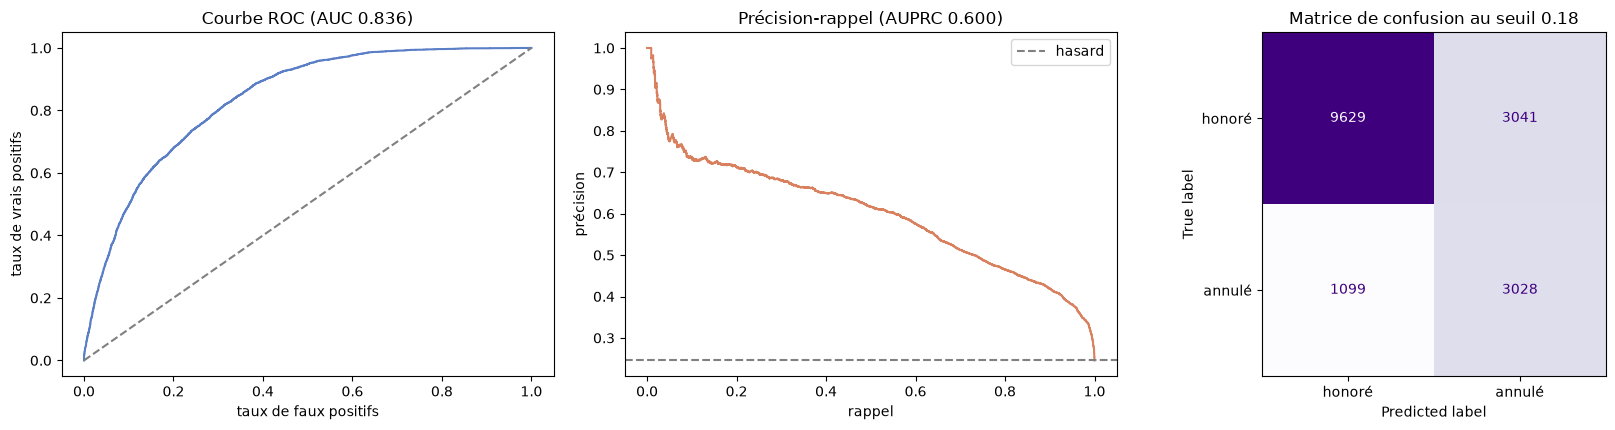

In [23]:
final = hgb
p_test = final.predict_proba(X_test)[:, 1]
cv = cross_val_score(pipeline(HistGradientBoostingClassifier(max_iter=400, learning_rate=0.08, random_state=SEED), scale=False),
                     X_train, y_train, cv=TimeSeriesSplit(n_splits=4), scoring="average_precision")
print(f"Validation croisée chronologique (4 plis) : AUPRC {cv.mean():.3f} ± {cv.std():.3f}")
print(f"Test : AUPRC {average_precision_score(y_test, p_test):.3f} | AUC {roc_auc_score(y_test, p_test):.3f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
fpr, tpr, _ = roc_curve(y_test, p_test)
axes[0].plot(fpr, tpr, color="#5B7FC7"); axes[0].plot([0, 1], [0, 1], "--", color="grey")
axes[0].set(title=f"Courbe ROC (AUC {roc_auc_score(y_test, p_test):.3f})", xlabel="taux de faux positifs", ylabel="taux de vrais positifs")
prec, rec, _ = precision_recall_curve(y_test, p_test)
axes[1].plot(rec, prec, color="#D9805F"); axes[1].axhline(y_test.mean(), ls="--", color="grey", label="hasard")
axes[1].set(title=f"Précision-rappel (AUPRC {average_precision_score(y_test, p_test):.3f})", xlabel="rappel", ylabel="précision"); axes[1].legend()
ConfusionMatrixDisplay(confusion_matrix(y_test, p_test >= SEUIL_ECO), display_labels=["honoré", "annulé"]).plot(ax=axes[2], colorbar=False, cmap="Purples")
axes[2].set_title(f"Matrice de confusion au seuil {SEUIL_ECO:.2f}")
plt.tight_layout(); plt.show()

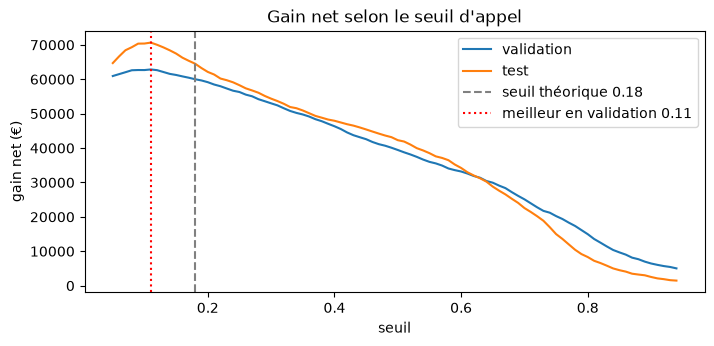

appeler tout le monde        :  16797 appels, gain net     36,785 €
n'appeler personne           :      0 appels, gain net          0 €
modèle, seuil 0.18           :   6069 appels, gain net     64,519 €
Seuil retenu sur la validation : 0.11 → gain net sur le test 70,657 €

Calibration sur le test (probabilité moyenne prédite contre taux réel) :
            proba prédite       annulation réelle
                     mean  size              mean
(0.0, 0.1]          0.036  7700             0.049
(0.1, 0.18]         0.138  3028             0.238
(0.18, 0.3]         0.230  2113             0.324
(0.3, 0.5]          0.390  1227             0.475
(0.5, 0.7]          0.609  1439             0.591
(0.7, 1.0]          0.788  1290             0.705

Au seuil 0.18 : précision 0.499, rappel 0.734


In [24]:
# Le seuil : gain net selon le seuil, d'abord sur la VALIDATION (pour choisir), puis vérifié sur le test
m_val = pipeline(HistGradientBoostingClassifier(max_iter=400, learning_rate=0.08, random_state=SEED), scale=False)
m_val.fit(fit_part[RAW_COLUMNS], fit_part[TARGET])
p_val = m_val.predict_proba(val[RAW_COLUMNS])[:, 1]
seuils = np.round(np.arange(0.05, 0.95, 0.01), 2)
gains_val = [gain_net(val[TARGET].to_numpy(), p_val, s) for s in seuils]
gains_test = [gain_net(y_test, p_test, s) for s in seuils]
SEUIL_VAL = float(seuils[int(np.argmax(gains_val))])

plt.figure(figsize=(8, 3.4))
plt.plot(seuils, gains_val, label="validation"); plt.plot(seuils, gains_test, label="test")
plt.axvline(SEUIL_ECO, ls="--", color="grey", label=f"seuil théorique {SEUIL_ECO:.2f}")
plt.axvline(SEUIL_VAL, ls=":", color="red", label=f"meilleur en validation {SEUIL_VAL:.2f}")
plt.xlabel("seuil"); plt.ylabel("gain net (€)"); plt.title("Gain net selon le seuil d'appel"); plt.legend(); plt.show()

for nom, appel in [("appeler tout le monde", np.ones_like(y_test, bool)), ("n'appeler personne", np.zeros_like(y_test, bool)),
                   (f"modèle, seuil {SEUIL_ECO:.2f}", p_test >= SEUIL_ECO)]:
    g = (y_test[appel] * TAUX_SUCCES * VALEUR).sum() - COUT_APPEL * appel.sum()
    print(f"{nom:28s} : {appel.sum():6d} appels, gain net {g:10,.0f} €")
print(f"Seuil retenu sur la validation : {SEUIL_VAL:.2f} → gain net sur le test {gain_net(y_test, p_test, SEUIL_VAL):,.0f} €")
calib = pd.DataFrame({"proba prédite": p_test, "annulation réelle": y_test}).groupby(
    pd.cut(p_test, [0, 0.1, 0.18, 0.3, 0.5, 0.7, 1]), observed=True).agg(["mean", "size"]).iloc[:, [0, 1, 2]].round(3)
print("\nCalibration sur le test (probabilité moyenne prédite contre taux réel) :"); print(calib)
print(f"\nAu seuil {SEUIL_ECO:.2f} : précision {precision_score(y_test, p_test >= SEUIL_ECO):.3f}, rappel {recall_score(y_test, p_test >= SEUIL_ECO):.3f}")

### Choix du seuil

- **Au seuil théorique de 0,18**, le modèle fait appeler 6 069 réservations sur 16 797 (36 %). Précision 0,50 (un appel sur deux tombe sur une vraie annulation), rappel 0,73 (on joint 73 % des futures annulations). Gain net de **64 519 €** sur la période de test, contre 36 785 € si l'on appelle tout le monde et 0 € si l'on n'appelle personne.
- **Le seuil 0,18 suppose des probabilités bien calibrées.** Le tableau de calibration montre que le modèle **sous-estime le risque** des réservations récentes entre 0,1 et 0,3 (par exemple 0,14 prédit pour 0,24 observé) : la période de test annule davantage que l'entraînement (dérive).
- **Le seuil choisi sur la validation, 0,11**, donne 70 657 € sur le test (+6 000 €). On le recommande à l'équipe commerciale ; l'application garde 0,18 par défaut (seuil économique) et le curseur permet de descendre à 0,11.

## 9. Diagnostic : sur- ou sous-apprentissage ?

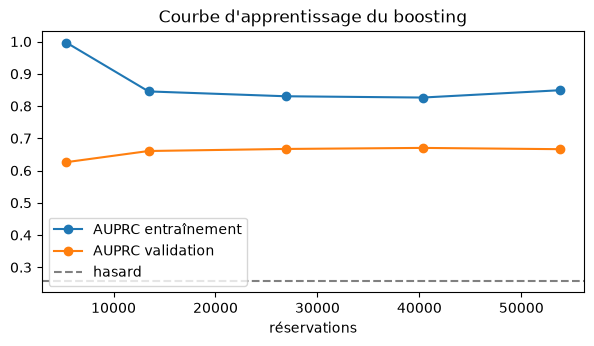

 réservations  AUPRC entraînement  AUPRC validation
         5374               0.997             0.626
        13437               0.845             0.661
        26874               0.830             0.667
        40311               0.826             0.670
        53749               0.849             0.666
Écart entraînement - test des paliers :
modèle
1. Baseline (taux moyen)                 -0.001
2a. Logistique sans variables dérivées    0.081
2b. Logistique avec variables dérivées    0.132
3a. Arbre, profondeur 3                   0.051
3b. Arbre, profondeur 10 (validation)     0.195
3c. Arbre, profondeur illimitée           0.658
4. Forêt aléatoire (300 arbres)           0.318
5. Gradient boosting (HistGB)             0.222
6. Bonus : MLP (64, 64)                   0.218


In [25]:
# Courbe d'apprentissage chronologique : on entraîne sur les n réservations les plus récentes
# de la partie d'entraînement, et on mesure l'AUPRC sur la validation (période suivante).
lc = []
for f in [0.1, 0.25, 0.5, 0.75, 1.0]:
    sub = fit_part.iloc[-int(len(fit_part) * f):]
    m = pipeline(HistGradientBoostingClassifier(max_iter=400, learning_rate=0.08, random_state=SEED), scale=False)
    m.fit(sub[RAW_COLUMNS], sub[TARGET])
    lc.append({"réservations": len(sub),
               "AUPRC entraînement": average_precision_score(sub[TARGET], m.predict_proba(sub[RAW_COLUMNS])[:, 1]),
               "AUPRC validation": average_precision_score(val[TARGET], m.predict_proba(val[RAW_COLUMNS])[:, 1])})
lc = pd.DataFrame(lc)
ax = lc.plot(x="réservations", y=["AUPRC entraînement", "AUPRC validation"], marker="o", figsize=(7, 3.4),
             title="Courbe d'apprentissage du boosting")
ax.axhline(val[TARGET].mean(), ls="--", color="grey", label="hasard"); ax.legend(); plt.show()
print(lc.round(3).to_string(index=False))
print("Écart entraînement - test des paliers :")
print((table["AUPRC entraînement"] - table["AUPRC test"]).round(3).to_string())

- **Pas de sous-apprentissage** : l'AUPRC de validation (0,63 à 0,67) est bien au-dessus du hasard (0,25) et de l'arbre de profondeur 3.
- **Sur-apprentissage contenu** : avec 5 374 réservations, le boosting apprend presque par cœur (0,997 en entraînement). À partir de 27 000, l'écart se stabilise autour de 0,17 et la validation atteint un **plateau vers 0,67**. Ajouter des données anciennes n'aide plus : le gain viendrait plutôt de nouvelles variables.
- **Comparaison des paliers** : l'arbre illimité a l'écart le plus fort (0,66), la forêt 0,32, le boosting 0,22, la logistique 0,13. Le boosting offre le meilleur compromis entre score et écart.

## 10. Interprétation : quelles variables comptent ?

Importance par permutation sur le test : on mélange une colonne **brute** et on mesure la perte d'AUPRC. Plus la perte est grande, plus la variable compte.

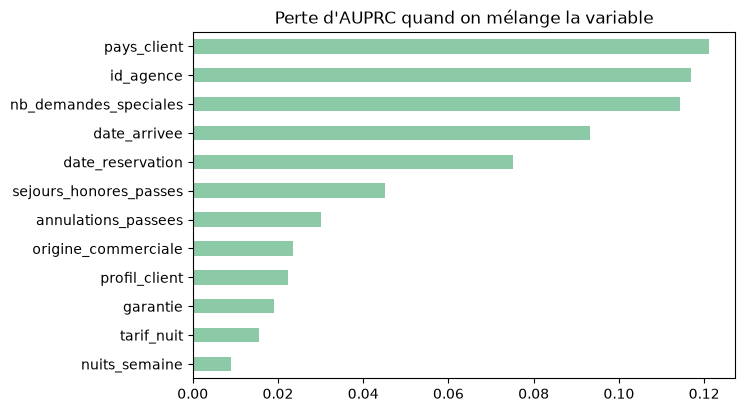

pays_client               0.121
id_agence                 0.117
nb_demandes_speciales     0.114
date_arrivee              0.093
date_reservation          0.075
sejours_honores_passes    0.045
annulations_passees       0.030
origine_commerciale       0.024
profil_client             0.022
garantie                  0.019
tarif_nuit                0.016
nuits_semaine             0.009
dtype: float64

In [26]:
imp = permutation_importance(final, X_test, y_test, scoring="average_precision", n_repeats=3, random_state=SEED, n_jobs=-1)
importance = pd.Series(imp.importances_mean, index=RAW_COLUMNS).sort_values()
importance.tail(12).plot.barh(figsize=(7, 4.5), color="#8CC9A6", title="Perte d'AUPRC quand on mélange la variable")
plt.show()
importance.sort_values(ascending=False).head(12).round(3)

### À expliquer à un responsable commercial

- **Le pays du client** : les clients français annulent beaucoup plus (52 % avant dédoublonnage) que les autres (14 % à 32 %). Hypothèse : réservations domestiques plus faciles à annuler. À surveiller sous l'angle de l'équité.
- **L'agence qui a vendu la réservation** : certaines agences en ligne apportent des clients qui annulent beaucoup plus. C'est un levier de négociation commerciale.
- **Les demandes spéciales** : un client qui demande quelque chose (lit bébé, étage) est engagé dans son séjour et annule rarement.
- **Les dates** (délai et saison) : plus l'arrivée est lointaine, plus le risque est élevé ; l'été et certains mois annulent davantage.
- **L'historique du client** : séjours déjà honorés (fidélité) et annulations passées.
- **L'origine commerciale et la garantie** : les groupes et les réservations « non remboursables » annulent le plus.

Un responsable peut retenir : *« une réservation lointaine, venant d'une agence en ligne, sans demande spéciale, par un client sans historique, est à appeler en priorité. »*

## 11. Sauvegarde

Le pipeline final est construit et sauvegardé par **`train.py`** (même préparation, même modèle) : il est évalué sur le test chronologique, puis réentraîné sur toutes les données avant d'être enregistré dans `model.pkl`, avec ses métadonnées dans `model_meta.json`.

In [27]:
import subprocess, sys, json
print(subprocess.run([sys.executable, "train.py"], capture_output=True, text=True).stdout)
print(json.dumps(json.load(open("model_meta.json")), indent=1, ensure_ascii=False)[:1500])

Évaluation sur le test chronologique : {'auprc_test': np.float64(0.5996), 'auc_test': np.float64(0.8361), 'precision_seuil': 0.4989, 'rappel_seuil': 0.7337, 'gain_net_test_euros': 64519.0, 'temps_entrainement_s': 11.1}
Pipeline sauvegardé dans model.pkl, métadonnées dans model_meta.json

{
 "version": "1.0.0",
 "date": "2026-10-15",
 "modele": "HistGradientBoostingClassifier (max_iter=400, learning_rate=0.08)",
 "seuil_par_defaut": 0.18,
 "variables_brutes": [
  "site",
  "date_reservation",
  "date_arrivee",
  "nuits_week_end",
  "nuits_semaine",
  "nb_adultes",
  "nb_enfants",
  "nb_bebes",
  "formule",
  "pays_client",
  "origine_commerciale",
  "canal_vente",
  "client_fidele",
  "annulations_passees",
  "sejours_honores_passes",
  "logement_demande",
  "garantie",
  "id_agence",
  "id_entreprise",
  "profil_client",
  "tarif_nuit",
  "nb_demandes_speciales"
 ],
 "champs_saisis": [
  "date_reservation",
  "date_arrivee",
  "nuits_week_end",
  "nuits_semaine",
  "nb_adultes",
  "pay